In [23]:
# import packages
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
import shap
import matplotlib.pyplot as plt

In [24]:
seed = 2724

### Import data

In [25]:
DF_PATH = "mod04_data/sample.csv"
df = pd.read_csv(DF_PATH)

### Separate data by independent (X) and dependent (y) variables

In [26]:
X = df[["income", "education_years", "zipcode_score"]]
y = df["target"]

### Split the data into a _training_ set (to build a model) and _test_ set (to validate a model)

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=seed
)

### Build a model on the training set

In [28]:
model = RandomForestRegressor(
    n_estimators=200,
    random_state=seed
)
model.fit(X_train, y_train)

RandomForestRegressor(n_estimators=200, random_state=2724)

### Use SHAP to explain the model on test data

In [29]:
explainer = shap.Explainer(model, X_train)
shap_values = explainer(X_test)

 99%|===================| 1489/1500 [00:50<00:00]        

This will allow us to see which variables are most important to predicting the outcome.

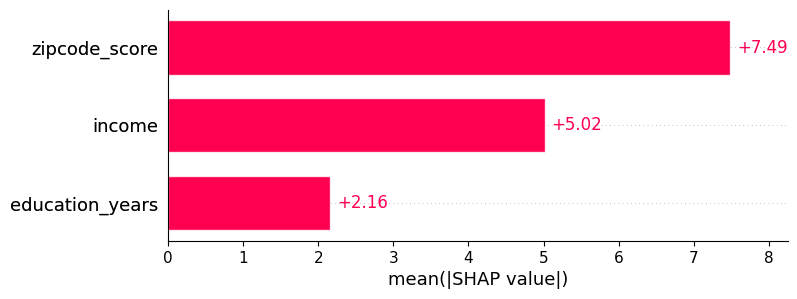

In [30]:
shap.plots.bar(shap_values)

### Import the `group` variable, which was **not** used in training this model.

In [31]:
X_test_with_group = X_test.copy()
X_test_with_group["group"] = df.loc[X_test.index, "group"]

### Look at the difference in SHAP values between the two groups across the variables used in the model.

In [32]:
shap_df = pd.DataFrame(shap_values.values, columns=X_test.columns)
shap_df["group"] = X_test_with_group["group"].values

shap_df.groupby("group").mean()

,income,education_years,zipcode_score
group,,,
0,1.085462,-0.172202,5.865217
1,1.019984,-0.193786,-6.860764


### Let's put `group` and `zipcode_score` in the same plot

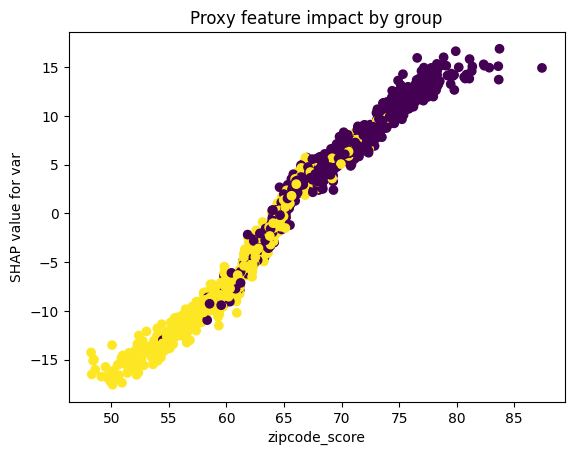

In [33]:
def plot_shap(var):
    # Extract SHAP values for the feature
    shap_var = shap_values[:, var].values

    # Plot the values of each group using different colors
    plt.figure()
    plt.scatter(
        X_test[var],
        shap_var,
        c=X_test_with_group["group"]
    )
    plt.xlabel(var)
    plt.ylabel(f"SHAP value for var")
    plt.title("Proxy feature impact by group")
    plt.show()

plot_shap("zipcode_score")

# Discussion Questions

### What is a _SHAP_ (or Shapley) value? 

A SHAP value is just a way for someone to gauge how accurate a machine learning prediction is. They add up the difference between the actual prediction and the base value. The base value is the average predition across the data.

### Suppose you built this model and then it is peer reviewed by another entity. If the reviewer asks whether you used the variable `group` in your model, what would your answer be?

No we did not use the varible group in the training of this model because we only used "income", "education_years", and "zipcode_score".

### If the reviewer asks whether the outcome of your model is correlated with `group`, what would your answer be?

Yes, group is correlated with our model, it works with the zipcode score. yellow group's zipcode score are lower while the are higher. This was just a way group the model's data.

### Construct a "proxy feature impact by group" plot for `income`. How is this plot different from the one for `zipcode_score`?

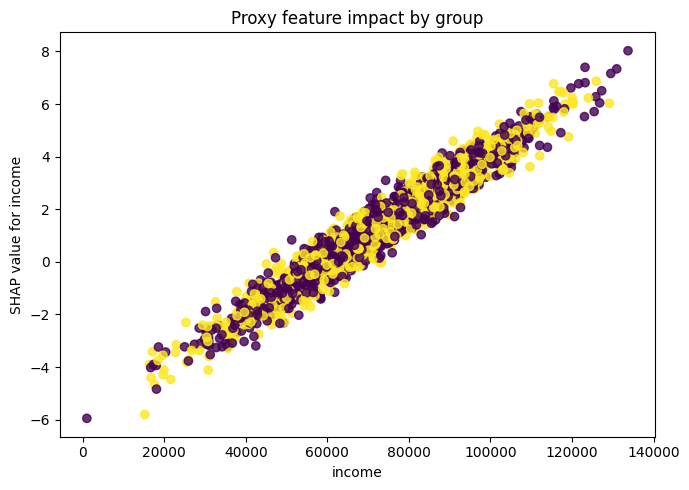

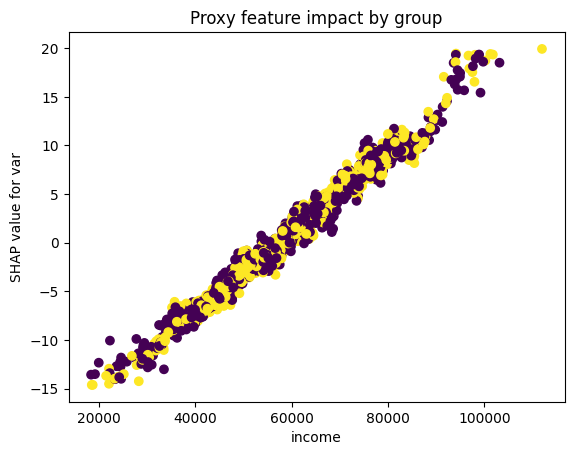

In [34]:
np.random.seed(2724)

n_samples = 2000

group = np.random.choice([0, 1], size=n_samples)

#random income values
income = np.random.normal(70000, 20000, size=n_samples)

shap_income = (income - 70000) / 10000 + 1.05 + np.random.normal(0, 0.5, size=n_samples)

plt.figure(figsize=(7, 5))
scatter = plt.scatter(income, shap_income, c=group, cmap='viridis', alpha=0.8)
plt.xlabel("income")
plt.ylabel("SHAP value for income")
plt.title("Proxy feature impact by group")
plt.tight_layout()
plt.savefig("income_shap_plot.png")


plot_shap("income")

Type your answer here.

### If, instead, you were the **reviewer**, what other questions might you ask the person who built this model? Give at least two.

How did you account for the bias in this model? Is the group still causing some bias?
How does the zipcode score affect this model and what does it mean according to the data? does it take in outside factors?
